In [1]:
import pandas as pd

filtered_df = pd.read_csv('datasets/coffee_dataset_for_learning.csv')

In [2]:
dummies = filtered_df['variety'].str.get_dummies(sep=",").add_prefix("variety_")
filtered_df = pd.concat([filtered_df, dummies], axis=1)
filtered_df.head()

,Unnamed: 0,country_of_origin,processing_method,variety,roast,note_keywords,binary_notes,target,first_binary_notes,first_target,...,variety_SL28,variety_SL34,variety_Sidamo,variety_Sidra,variety_Sulawesi,variety_Sumatra,variety_Sumatra Lintong,variety_Typica,variety_Yellow Bourbon,variety_Yirgacheffe
0,0,Tanzania,washed,Geisha,Medium-Light,"{'sweet', 'orange', 'citrus fruit', 'brown sug...","{'roasted': 0, 'spices': 0, 'nutty/cocoa': 0, ...","[0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","{'roasted': 0, 'spices': 0, 'nutty/cocoa': 0, ...","[0, 0, 0, 1, 0, 1, 0, 0, 0]",...,0,0,0,0,0,0,0,0,0,0
1,1,Burundi,washed,Bourbon,Medium-Light,"{'berry', 'red currant', 'apricot', 'grapefrui...","{'roasted': 0, 'spices': 0, 'nutty/cocoa': 0, ...","[0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","{'roasted': 0, 'spices': 0, 'nutty/cocoa': 0, ...","[0, 0, 0, 0, 0, 1, 0, 0, 0]",...,0,0,0,0,0,0,0,0,0,0
2,2,Colombia,natural,Huila,Medium-Light,"{'wine', 'berry', 'grape', 'alcohol/fermented'...","{'roasted': 0, 'spices': 1, 'nutty/cocoa': 0, ...","[0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, ...","{'roasted': 0, 'spices': 1, 'nutty/cocoa': 0, ...","[0, 1, 0, 0, 0, 1, 1, 0, 0]",...,0,0,0,0,0,0,0,0,0,0
3,3,Colombia,natural,Castillo,Medium-Light,"{'berry', 'fruit', 'blackberry', 'other fruit'...","{'roasted': 0, 'spices': 0, 'nutty/cocoa': 0, ...","[0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","{'roasted': 0, 'spices': 0, 'nutty/cocoa': 0, ...","[0, 0, 0, 0, 0, 1, 0, 0, 0]",...,0,0,0,0,0,0,0,0,0,0
4,4,Ethiopia,natural,Sidamo,Medium-Light,"{'berry', 'pomegranate', 'fruit', 'mango', 'ot...","{'roasted': 0, 'spices': 0, 'nutty/cocoa': 0, ...","[0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","{'roasted': 0, 'spices': 0, 'nutty/cocoa': 0, ...","[0, 0, 0, 0, 0, 1, 0, 0, 0]",...,0,0,1,0,0,0,0,0,0,0


In [3]:
import ast

cats = filtered_df["first_binary_notes"].apply(ast.literal_eval)

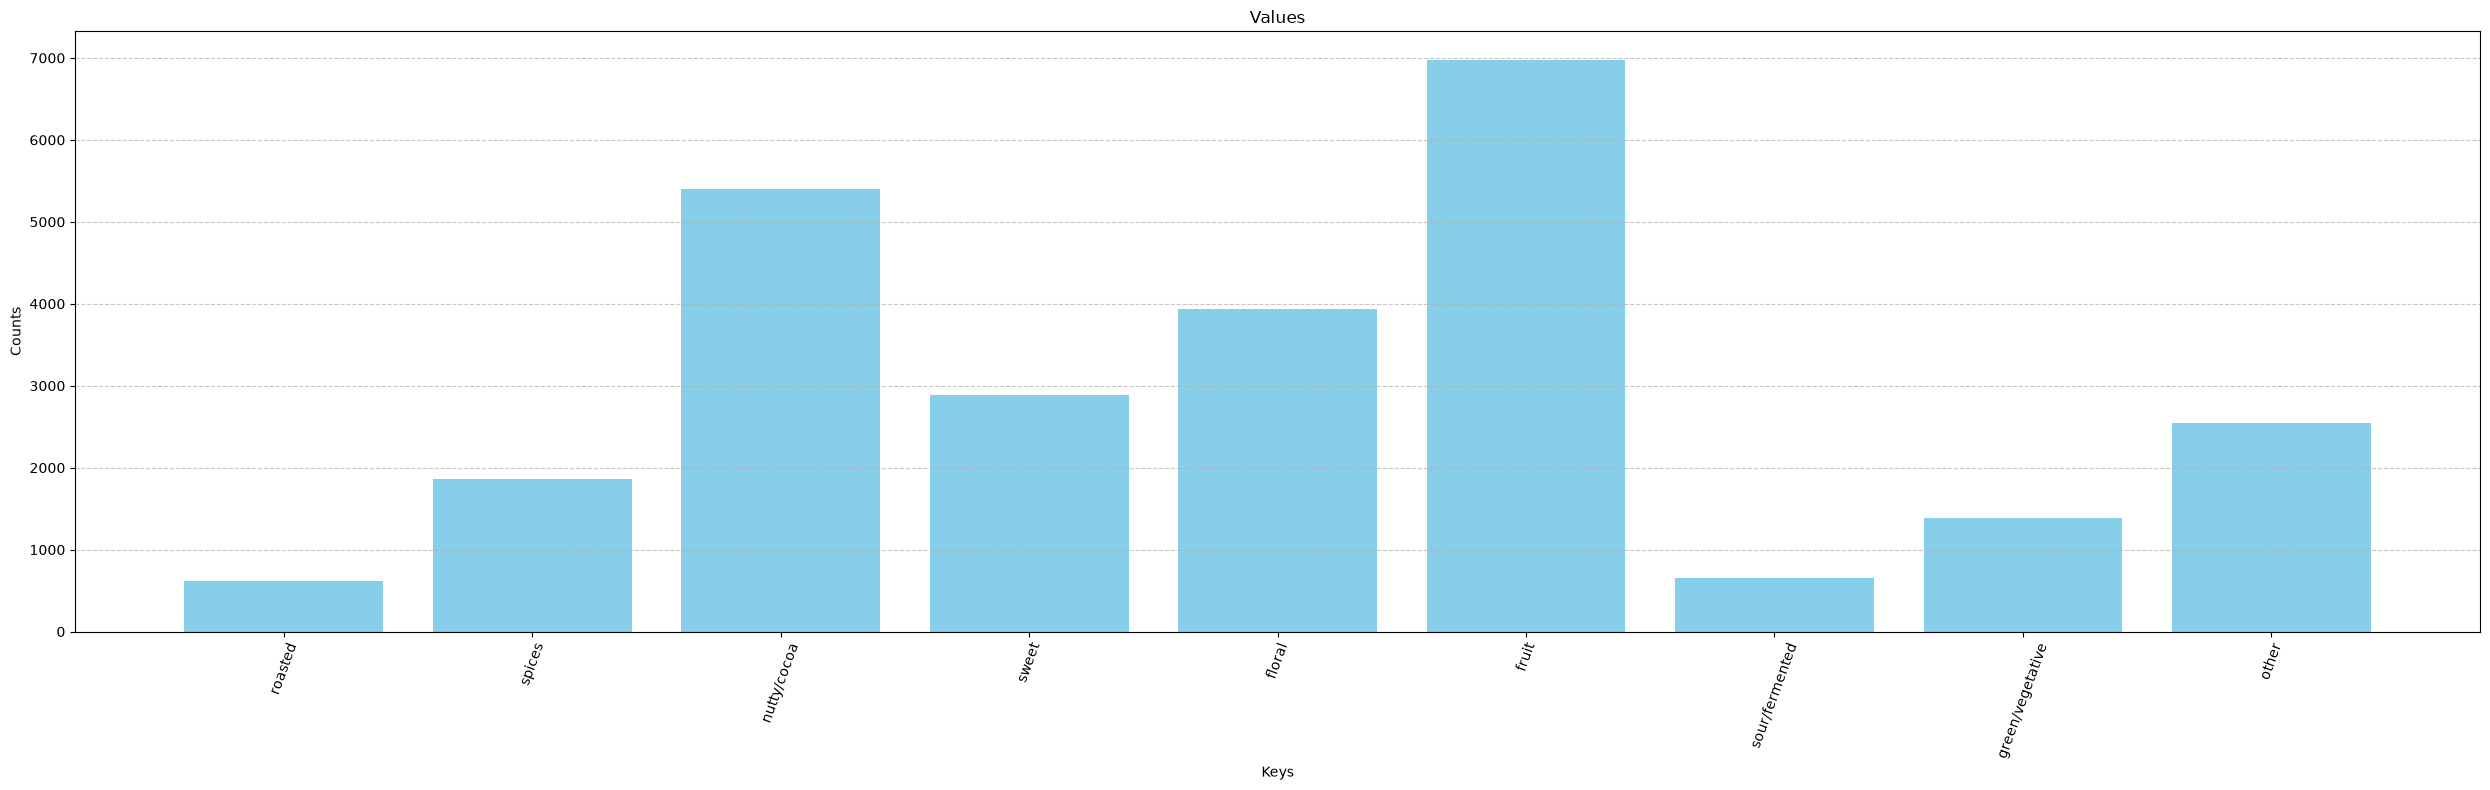

In [4]:
from collections import Counter
import ast

total_counter = Counter()
for group in cats:
    total_counter.update(group)

from matplotlib import pyplot as plt
keys = list(total_counter.keys())
values = list(total_counter.values())

plt.figure(figsize=(25, 8))
plt.bar(keys, values, color='skyblue')

plt.title(f'Values')
plt.xlabel('Keys')
plt.ylabel('Counts')
plt.xticks(rotation=70)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

In [5]:
from sklearn.model_selection import train_test_split
import numpy as np
import ast

X_columns = ['country_of_origin', 'processing_method', 'roast']
variety_cols = [col for col in filtered_df.columns if col.startswith("variety_")]
X_columns.extend(variety_cols)

X = filtered_df[X_columns]
y_matrix = np.array([ast.literal_eval(x) for x in filtered_df['first_target']], dtype=float)

X_train, X_test, y_train, y_test = train_test_split(X, y_matrix,
                                                    test_size=0.2,
                                                    random_state=42)

X_test, X_val, y_test, y_val = train_test_split(X_test, y_test,
                                                    test_size=0.5,
                                                    random_state=42)

In [6]:
from catboost import CatBoostClassifier

cat_features = ['country_of_origin', 'processing_method', 'roast']

model = CatBoostClassifier(
    loss_function='MultiLogloss',
    iterations=170,
    learning_rate=0.1,
    depth=3,
    random_seed=42,
    l2_leaf_reg=5,
    colsample_bylevel=1.0,
    subsample=1.0
    #task_type='GPU'
)

model.fit(
    X_train,
    y_train,
    eval_set=(X_val, y_val),
    cat_features=cat_features,
    verbose=10
)

0:	learn: 0.6504431	test: 0.6511257	best: 0.6511257 (0)	total: 92.5ms	remaining: 15.6s
10:	learn: 0.5059825	test: 0.5128159	best: 0.5128159 (10)	total: 404ms	remaining: 5.84s
20:	learn: 0.4891880	test: 0.4984634	best: 0.4984634 (20)	total: 690ms	remaining: 4.9s
30:	learn: 0.4847047	test: 0.4953577	best: 0.4953577 (30)	total: 982ms	remaining: 4.4s
40:	learn: 0.4823306	test: 0.4937479	best: 0.4937479 (40)	total: 1.28s	remaining: 4.02s
50:	learn: 0.4809624	test: 0.4930736	best: 0.4930736 (50)	total: 1.57s	remaining: 3.67s
60:	learn: 0.4799013	test: 0.4925740	best: 0.4925740 (60)	total: 1.89s	remaining: 3.38s
70:	learn: 0.4789553	test: 0.4919865	best: 0.4919786 (69)	total: 2.18s	remaining: 3.04s
80:	learn: 0.4781007	test: 0.4916986	best: 0.4916986 (80)	total: 2.47s	remaining: 2.72s
90:	learn: 0.4773394	test: 0.4913508	best: 0.4913508 (90)	total: 2.76s	remaining: 2.39s
100:	learn: 0.4764856	test: 0.4909874	best: 0.4909874 (100)	total: 3.04s	remaining: 2.08s
110:	learn: 0.4756787	test: 0.490

CatBoostClassifier(colsample_bylevel=1.0, depth=3, iterations=170, l2_leaf_reg=5, learning_rate=0.1, loss_function='MultiLogloss', random_seed=42, subsample=1.0)

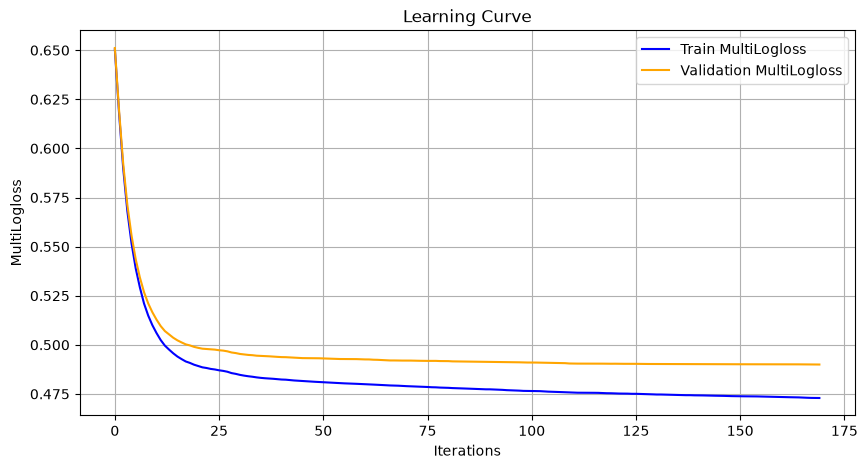

In [7]:
evals_result = model.get_evals_result()

train_loss = evals_result['learn']['MultiLogloss']
val_loss = evals_result['validation']['MultiLogloss']

plt.figure(figsize=(10, 5))
plt.plot(train_loss, label='Train MultiLogloss', color='blue')
plt.plot(val_loss, label='Validation MultiLogloss', color='orange')

plt.xlabel('Iterations')
plt.ylabel('MultiLogloss')
plt.title('Learning Curve')
plt.legend()
plt.grid(True)
plt.show()

In [9]:
y_pred = model.predict_proba(X_test)

In [10]:
def get_notes_from_pred(predictions, real, notes_dict):
  pred_notes = []
  for pred, note in zip(predictions, notes_dict):
    if pred == 1:
      pred_notes.append(note)

  real_notes = []
  for r, note in zip(real, notes_dict):
    if r == 1:
      real_notes.append(note)

  return pred_notes, real_notes

keys = ast.literal_eval(filtered_df['first_binary_notes'][0]).keys()
for i in range(len(y_pred)):
  print(f"coffee: {X_test.iloc[i]['country_of_origin']} {X_test.iloc[i]['roast']} {X_test.iloc[i]['processing_method']}")
  print(f"predictions: {y_pred[i]}")
  print(f"real: {y_test[i]}")

coffee: Indonesia Medium-Light washed
predictions: [0.05097926 0.22066116 0.49319261 0.33182526 0.39217582 0.78871182
 0.06511847 0.15223777 0.26547568]
real: [0. 0. 1. 0. 0. 1. 0. 1. 0.]
coffee: Indonesia Dark washed
predictions: [0.26701942 0.36435567 0.50716591 0.24259688 0.15520593 0.36485285
 0.12488786 0.22663109 0.52262702]
real: [0. 0. 1. 0. 0. 0. 0. 0. 0.]
coffee: Other Very Dark other
predictions: [0.16374595 0.30270016 0.58792902 0.23349186 0.16107268 0.36346208
 0.06912184 0.14716894 0.43104431]
real: [1. 0. 1. 0. 0. 1. 0. 0. 0.]
coffee: Guatemala Medium washed
predictions: [0.02962341 0.13677654 0.70171151 0.36667926 0.43548776 0.79638446
 0.04128757 0.15649101 0.30641339]
real: [0. 0. 1. 0. 0. 1. 0. 0. 1.]
coffee: Kenya Medium other
predictions: [0.03015313 0.22944483 0.52649795 0.3567741  0.54173443 0.85667343
 0.05703799 0.15969809 0.22193153]
real: [1. 1. 1. 0. 1. 0. 1. 0. 0.]
coffee: Panama Medium-Dark other
predictions: [0.05510873 0.22793227 0.66089483 0.31610564 0.

Post process predictions

In [12]:
label_names = ['roasted', 'spices', 'nutty/cocoa', 'sweet', 'floral', 'fruit', 'sour/fermented', 'green/vegetative', 'other']

best_thresholds = [0.1, 0.15, 0.4, 0.3, 0.2, 0.5, 0.05, 0.1, 0.15]
class_boosts = {
    6: 2,
    7: 1.5,
    0: 1.25,
    1: 1,
    2: 1.0,
    3: 1,
    4: 1.0,
    5: 1.0,
    8: 1,
}


In [13]:
import numpy as np

predicted_labels_text = []
int_probs = []

for row_probs in y_pred:
    passed_classes = []
    for i, p in enumerate(row_probs):
        threshold = best_thresholds[i]
        if p > threshold:
            boosted_score = p * class_boosts.get(i, 1.0)
            passed_classes.append((i, boosted_score, p))

    passed_classes.sort(key=lambda x: x[1], reverse=True)

    selected_classes = []

    if len(passed_classes) > 0:
        selected_classes.append(passed_classes[0])

        for i in range(1, min(len(passed_classes), 4)):
            current_score = passed_classes[i][1]
            prev_score = passed_classes[i - 1][1]

            confidence_ratio = current_score / prev_score

            if confidence_ratio < 0.5:
                break

            selected_classes.append(passed_classes[i])

    indices = [item[0] for item in selected_classes]

    int_prob = [1 if i in indices else 0 for i in range(len(row_probs))]
    int_probs.append(int_prob)

    names = [label_names[i] for i in indices]
    predicted_labels_text.append(names)

In [14]:
true_labels_text = []

for row_labels in y_test:
    indices = [i for i, val in enumerate(row_labels) if val == 1.0]
    names = [label_names[i] for i in indices]
    true_labels_text.append(names)

In [15]:
from sklearn.metrics import f1_score, hamming_loss, classification_report

f1_macro = f1_score(y_test, int_probs, average='macro')
f1_micro = f1_score(y_test, int_probs, average='micro')
f1_samples = f1_score(y_test, int_probs, average='samples')

print(f"F1-score (Macro): {f1_macro:.4f}")
print(f"f1_score (Micro): {f1_micro:.4f}")
print(f"f1_score (Samples): {f1_samples:.4f}")

h_loss = hamming_loss(y_test, int_probs)
print(f"Hamming Loss: {h_loss:.4f}")

report = classification_report(y_test, int_probs, target_names=[f"class_{i}" for i in range(9)])
print(report)

F1-score (Macro): 0.4202
f1_score (Micro): 0.6065
f1_score (Samples): 0.5903
Hamming Loss: 0.2927
              precision    recall  f1-score   support

     class_0       0.16      0.17      0.17        63
     class_1       0.26      0.16      0.20       198
     class_2       0.60      0.97      0.74       544
     class_3       0.34      0.63      0.44       291
     class_4       0.45      0.91      0.60       375
     class_5       0.79      0.93      0.85       688
     class_6       0.16      0.11      0.13        63
     class_7       0.39      0.18      0.24       135
     class_8       0.39      0.42      0.40       260

   micro avg       0.53      0.72      0.61      2617
   macro avg       0.39      0.50      0.42      2617
weighted avg       0.52      0.72      0.59      2617
 samples avg       0.53      0.74      0.59      2617



/Users/karina/PycharmProjects/Coffee_cupper/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in samples with no true labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [16]:
for i in range(len(y_test)):
    print(f"Example {i+1}:")
    print(f"coffee: {X_test.iloc[i]['country_of_origin']} {X_test.iloc[i]['roast']} {X_test.iloc[i]['processing_method']}")
    print(f"  Real labels:    {true_labels_text[i]}")
    print(f"  Predictions:     {predicted_labels_text[i]}")
    print(f"  Raw probs: {np.round(y_pred[i], 2)}")
    print("-" * 40)

Example 1:
coffee: Indonesia Medium-Light washed
  Real labels:    ['nutty/cocoa', 'fruit', 'green/vegetative']
  Predictions:     ['fruit', 'nutty/cocoa', 'floral', 'sweet']
  Raw probs: [0.05 0.22 0.49 0.33 0.39 0.79 0.07 0.15 0.27]
----------------------------------------
Example 2:
coffee: Indonesia Dark washed
  Real labels:    ['nutty/cocoa']
  Predictions:     ['other', 'nutty/cocoa', 'spices', 'green/vegetative']
  Raw probs: [0.27 0.36 0.51 0.24 0.16 0.36 0.12 0.23 0.52]
----------------------------------------
Example 3:
coffee: Other Very Dark other
  Real labels:    ['roasted', 'nutty/cocoa', 'fruit']
  Predictions:     ['nutty/cocoa', 'other', 'spices', 'green/vegetative']
  Raw probs: [0.16 0.3  0.59 0.23 0.16 0.36 0.07 0.15 0.43]
----------------------------------------
Example 4:
coffee: Guatemala Medium washed
  Real labels:    ['nutty/cocoa', 'fruit', 'other']
  Predictions:     ['fruit', 'nutty/cocoa', 'floral', 'sweet']
  Raw probs: [0.03 0.14 0.7  0.37 0.44 0.8  0.

In [58]:
model.save_model('models/catboost_model.cbm')